## Experiment 5: Data Visualization using Matplotlib

**Aim:** To analyze Air Quality Index (AQI) trends in a city dataset and visualize the pollutant data using matplotlib plots.

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(4)
dates = pd.date_range("2026-01-01", periods=90)
df = pd.DataFrame({
    "date": dates,
    "pm25": np.random.normal(80, 25, 90).clip(10, 200),
    "pm10": np.random.normal(120, 35, 90).clip(20, 300),
    "co": np.random.normal(1.2, 0.4, 90).clip(0.2, 3),
})
df.head()

,date,pm25,pm10,co
0,2026-01-01,81.264043,121.701105,1.288901
1,2026-01-02,92.498783,126.602617,1.621440
2,2026-01-03,55.102277,127.325972,0.946457
3,2026-01-04,97.339963,106.894428,1.051759
4,2026-01-05,69.542462,153.414451,1.014582


In [3]:
df["aqi"] = (df["pm25"] * 1.2 + df["pm10"] * 0.5).astype(int)
print("AQI min:", df["aqi"].min(), " AQI max:", df["aqi"].max())

AQI min: 63  AQI max: 232


In [4]:
print("missing values:")
print(df.isnull().sum())

missing values:
date    0
pm25    0
pm10    0
co      0
aqi     0
dtype: int64


In [5]:
print(df.describe())

                      date        pm25        pm10         co         aqi
count                   90   90.000000   90.000000  90.000000   90.000000
mean   2026-02-14 12:00:00   80.918911  122.458523   1.221775  157.844444
min    2026-01-01 00:00:00   20.505618   51.189485   0.411299   63.000000
25%    2026-01-23 06:00:00   63.741348  103.431085   1.007870  135.000000
50%    2026-02-14 12:00:00   81.312431  121.526669   1.142707  156.500000
75%    2026-03-08 18:00:00   96.871658  143.381380   1.503508  179.000000
max    2026-03-31 00:00:00  141.914604  197.124741   2.074339  232.000000
std                    NaN   25.418651   32.207356   0.388954   33.402520


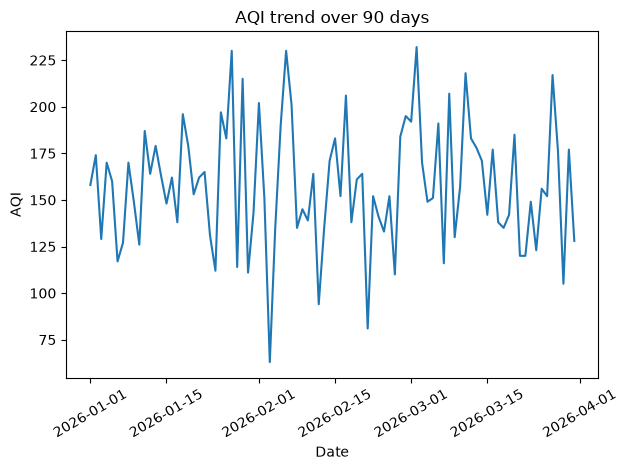

In [6]:
plt.plot(df["date"], df["aqi"])
plt.title("AQI trend over 90 days")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

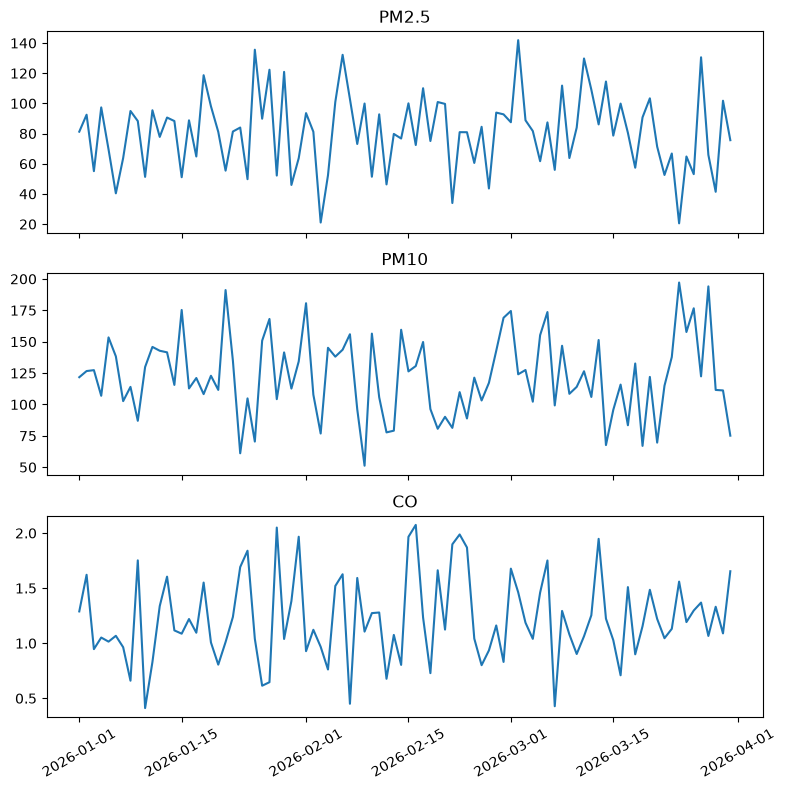

In [7]:
fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
ax[0].plot(df["date"], df["pm25"])
ax[0].set_title("PM2.5")
ax[1].plot(df["date"], df["pm10"])
ax[1].set_title("PM10")
ax[2].plot(df["date"], df["co"])
ax[2].set_title("CO")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
weekly = df.set_index("date")["aqi"].resample("W").mean()
print(weekly)

date
2026-01-04    157.750000
2026-01-11    148.000000
2026-01-18    164.285714
2026-01-25    157.000000
2026-02-01    171.142857
2026-02-08    157.857143
2026-02-15    147.285714
2026-02-22    150.571429
2026-03-01    158.142857
2026-03-08    173.714286
2026-03-15    168.428571
2026-03-22    145.285714
2026-03-29    154.000000
2026-04-05    152.500000
Freq: W-SUN, Name: aqi, dtype: float64


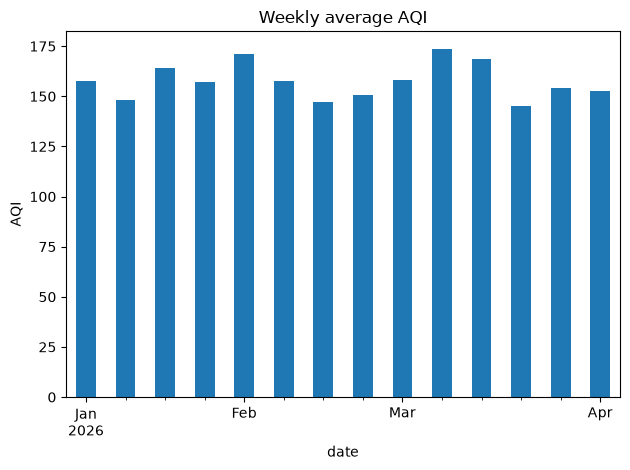

In [9]:
weekly.plot(kind="bar")
plt.title("Weekly average AQI")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()

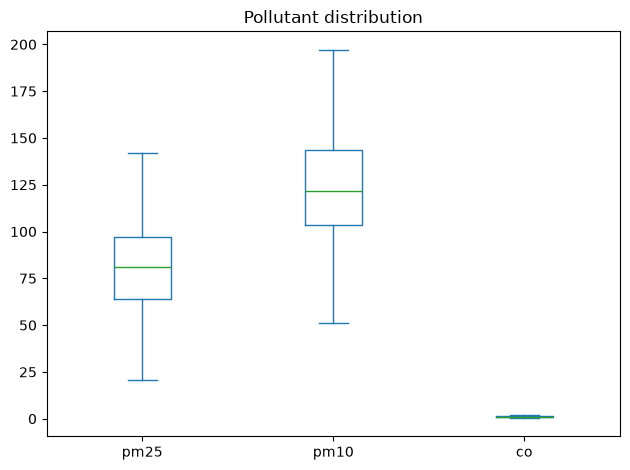

In [10]:
df[["pm25", "pm10", "co"]].plot(kind="box")
plt.title("Pollutant distribution")
plt.tight_layout()
plt.show()

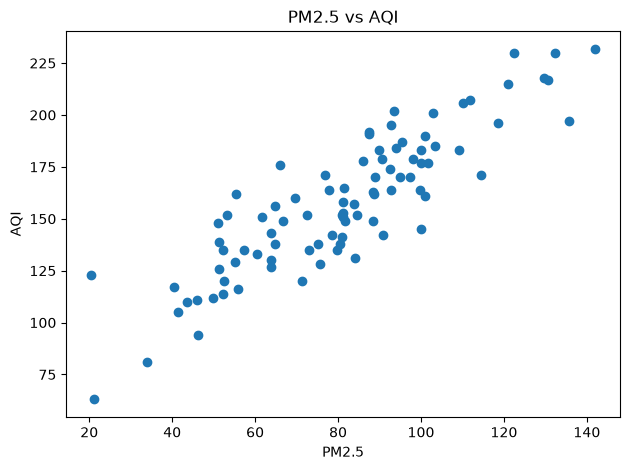

In [11]:
plt.scatter(df["pm25"], df["aqi"])
plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()

In [12]:
print("done")

done
